# Scan pipeline: orbit video to posed cameras

What `scripts/09_scan_object.py` does before splat training: keyframes, COLMAP SfM, and the object frame.

- **Modules:** `hurobo.scan` (`KeyframeSampler`, `SfmReconstructor`, `object_frame_from_orbit`), `hurobo.utils.viewer`
- **Data:** the committed-by-script outputs of the dummy fruit-bowl clip under `data/scans/dummy_fruit_bowl/`

This notebook only *reads* the finished reconstruction (fast). To redo it:
`uv run python scripts/09_scan_object.py data/raw/dummy_orbits/<clip>.mp4 --name dummy_fruit_bowl`

In [1]:
from hurobo.utils.notebook import setup_notebook

ROOT = setup_notebook()  # chdir to the repo root and set MUJOCO_GL=egl; must precede any mujoco import

In [2]:
import numpy as np

from hurobo.scan import largest_model, load_sparse_models, object_frame_from_orbit, sfm_result_from_model
from hurobo.utils.plotting import plot_image_row
from hurobo.utils.viewer import sfm_figure

SCAN_DIR = ROOT / "data/scans/dummy_fruit_bowl"
models = load_sparse_models(SCAN_DIR / "colmap/sparse")
model = largest_model(models)  # same choice SfmReconstructor makes
print(
    f"{len(models)} sub-model(s); largest: {model.num_reg_images()} images, "
    f"{model.num_points3D():,} points, "
    f"mean reprojection error {model.compute_mean_reprojection_error():.2f} px"
)
sfm = sfm_result_from_model(model)  # poses and points only; no pixels needed for this notebook

2 sub-model(s); largest: 120 images, 11,884 points, mean reprojection error 0.68 px


## Cameras and sparse points in the SfM frame
The SfM frame is arbitrary in position, orientation and scale. Red pyramids are the registered keyframes.

In [3]:
sfm_figure(
    sfm.points_world, sfm.colors, sfm.t_world_cam_list, title="SfM frame: sparse points + keyframe cameras"
).show()

## Object frame from the orbit
`object_frame_from_orbit` finds the orbit plane (camera centres) and makes its normal +z, with the base at z=0. Afterwards the object sits upright on the origin, which is what `SplatFit.MATCH_BODY_XY` assumes.

In [4]:
sfm_obj = sfm.in_frame(object_frame_from_orbit(sfm))

sfm_figure(
    sfm_obj.points_world,
    sfm_obj.colors,
    sfm_obj.t_world_cam_list,
    title="Object frame: z up the orbit axis, base at z=0",
).show()
z_obj = sfm_obj.points_world[:, 2]
print(
    f"object-frame z range of sparse points: {np.percentile(z_obj, 2):.3f} .. {np.percentile(z_obj, 98):.3f}"
)

object-frame z range of sparse points: -0.000 .. 1.171


## Photo vs splat
Held-out-style check written by the script: the real keyframe next to the trained splat rendered from the same pose.

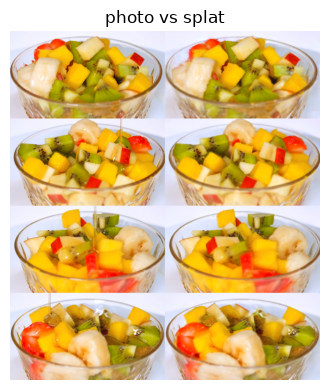

In [5]:
import matplotlib.pyplot as plt

plot_image_row({"photo vs splat": plt.imread(SCAN_DIR / "preview_photo_vs_splat.png")}, height_in=4)